# Example: What Does a Rule Do in a Wolfram Market?
In this example, we look at what one rule does in a Wolfram market. We read the table of one rule, run a market in which every interior trader follows that rule, and then compare it with a market that follows a second rule.

> __Learning Objectives:__
>
> By the end of this example, you should be able to:
> * __Read a rule number:__ Turn a rule number into its table, the next intention of a trader for each sum of its four neighbors' intentions.
> * __Watch a rule act on the grid:__ Run a market in which every interior trader follows the rule, and use the grid, the intentions, and the share price to describe what the rule does.
> * __Compare two rules:__ Run a second market that follows a different rule, and use the two grids and the two share prices to explain what the rule changes.

Let's get started!
___

## Setup, Data, and Prerequisites
First, we set up the computational environment by including the `Include.jl` file and loading any needed resources.

> __Include:__ The [`include(...)` command](https://docs.julialang.org/en/v1/base/base/#include) evaluates the contents of the input source file, `Include.jl`, in the notebook's global scope. The `Include.jl` file sets paths, loads required external packages, etc. For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/).

Let's set up our code environment:

In [1]:
include(joinpath(@__DIR__, "Include.jl")); # include the Include.jl file
import VLQuantitativeFinancePackage.WolframMarkets as WM; # the Wolfram market simulator, qualified so its names stay separate

  Activating project at `~/Desktop/julia_work/CHEME-5660-CourseRepository-Fall-2026`


For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/) and the [CHEME 5660 Quantitative Finance Package documentation](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/).


### Constants
Next, let's set the constants. The first two constants are the rule number and a second rule number, which we compare with the first in Task 3. One step lasts `Δt` years, and the dealer's share price gets noise with annualized volatility `σ_S` at each step.

Change the rule numbers and run the cells again:

In [ ]:
# the rules -
baseline_rule = 19280; # rule number that every interior trader follows, from 0 to 19682; the default is the baseline rule of the lecture
switch_rule = 19286; # second rule number, for Task 3; the default is the switch rule of the lecture

# Case: Bubble and Crash
baseline_rule = 19287;
switch_rule = 19341;

# the 18 rules that differ from Rule 19280 in one entry (two other intentions for each of the nine sums) -
# sum 0 (Sell under 19280): Buy gives 19278, Hold gives 19279
# sum 1 (Buy under 19280):  Hold gives 19283, Sell gives 19286
# sum 2 (Buy under 19280):  Hold gives 19289, Sell gives 19298
# sum 3 (Buy under 19280):  Hold gives 19307, Sell gives 19334
# sum 4 (Hold under 19280): Buy gives 19199, Sell gives 19361
# sum 5 (Hold under 19280): Buy gives 19037, Sell gives 19523
# sum 6 (Sell under 19280): Buy gives 17822, Hold gives 18551
# sum 7 (Sell under 19280): Buy gives 14906, Hold gives 17093
# sum 8 (Sell under 19280): Buy gives 6158, Hold gives 12719

# the market -
L = 64; # grid size (L × L traders, including the edge)
h = 100.0; # dealer depth; a small value (for example 1.0) makes the price move a long way for a given net order
boundary_mode = :endogenous; # edge traders: :endogenous (active), :hold (held), or :random (random draws)
random_probabilities = (1/3, 1/3, 1/3); # probabilities of (Buy, Hold, Sell) for :random edge traders; ignored otherwise
seed = 1; # starting market; each seed gives a different random start
number_of_steps = 5000; # steps we run

# the time step and the noise in the dealer's share price -
Δt = 1/(252*390); # length of one step (years), one minute of a 390-minute trading day
σ_S = 0.2; # annualized volatility of the noise in the dealer's share price (1/√yr); the noise added in one step has standard deviation σ_S√Δt, and 0.0 gives no noise

# names and colors used in every plot -
intention_names = ["Buy", "Hold", "Sell"]; # the intentions with codes 0, 1, and 2
intention_colors = [parse(Colorant, "#0072B2"), parse(Colorant, "#AAAAAA"), parse(Colorant, "#D55E00")]; # Buy is blue, Hold is gray, Sell is orange
color_rule = :navy; # the market that follows baseline_rule
color_compare = :red; # the market that follows switch_rule

___

## Task 1: Read the Rule
In this task, we turn the rule number into its table. Each interior trader adds up the intentions of its four neighbors, with Buy counted as `0`, Hold as `1`, and Sell as `2`. The sum runs from `0` (four Buy neighbors) to `8` (four Sell neighbors). 

A __rule__ is a table with the trader's next intention for each sum, and the __rule number__ is those nine entries read as one number in base 3.

[The rule_table(...) function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/) returns the nine entries of a rule number, ordered from sum `0` to sum `8`. We store the entries in the `entries::Vector{Int64}` variable:

In [3]:
entries = let

    # get the nine entries of the rule: table[c + 1] is the next intention for neighbor sum c -
    table = WM.rule_table(baseline_rule);

    # read the entries back as one number in base 3 -
    number = 0;
    for c ∈ 0:8
        number = number + table[c + 1]*3^c;
    end
    println("Rule $(baseline_rule) in base 3, from sum 8 down to sum 0: $(join(reverse(table)))");

    # checks -
    @assert length(table) == 9 "one entry for each neighbor sum from 0 to 8"
    @assert number == baseline_rule "the entries, read in base 3, give back the rule number"

    # return -
    table
end;

Rule 3720 in base 3, from sum 8 down to sum 0: 012002210


`Unhide` the code block below to see how we drew the rule table with the `plot_rule(...)` helper in `src/Helper.jl`. Each tile shows the next intention of a trader for one sum of its neighbors' intentions.

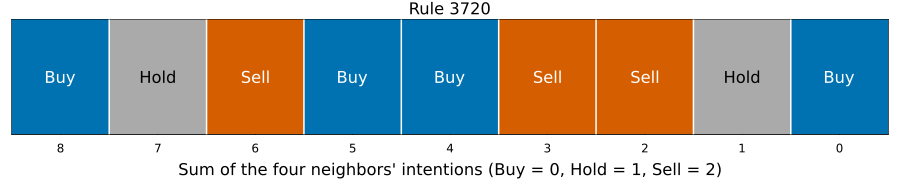

In [4]:
let
    # draw the nine entries: sum 8 on the left, sum 0 on the right -
    plot_rule(entries; colors = intention_colors, names = intention_names, title_text = "Rule $(baseline_rule)")
end

___

## Task 2: Watch the Rule Act on the Grid
In this task, we give the rule to every interior trader, run the market, and look at the grid at several steps.

At each step, the dealer fills the orders, and then every interior trader reads its next intention from the rule table. The `run_rule_market(...)` function in `src/Helper.jl` runs the market and saves the grid at the steps we pass in `snapshot_steps`.

We store the market in the `market::MyModelBSimulationResult` variable:

In [5]:
market = let

    # the random-edge probabilities only matter for :random edge traders -
    kw = NamedTuple();
    if boundary_mode == :random
        kw = (random_edge_probabilities = random_probabilities,);
    end

    # run the market, save the grid at every step, and time it -
    saved_steps = collect(0:number_of_steps);
    t_run = @elapsed result = run_rule_market(; rule = baseline_rule, L = L, h = h, seed = seed, boundary_mode = boundary_mode,
        steps = number_of_steps, σ_S = σ_S, Δt = Δt, snapshot_steps = saved_steps, kw...);
    println("run time: $(round(t_run; digits = 1)) seconds; saved grids: $(length(saved_steps))");

    # checks -
    @assert length(result.prices) == number_of_steps + 1 "one price for each step, including step 0"
    @assert length(result.frames) == number_of_steps + 1 "one saved grid for each step, including step 0"

    # return -
    result
end;

run time: 2.2 seconds; saved grids: 5001


Let's look at the grid at the steps in `steps_to_visualize`, from the start to the last step. Each tile is one interior trader: Buy is blue, Hold is gray, and Sell is orange:

In [6]:
steps_to_visualize = [0, 2, 5, 20, 1000, 5000]; # time steps to visualize, in order

`Unhide` the code block below to see how we drew the grids with the `plot_grid(...)` helper function in the `src/Helper.jl` file.

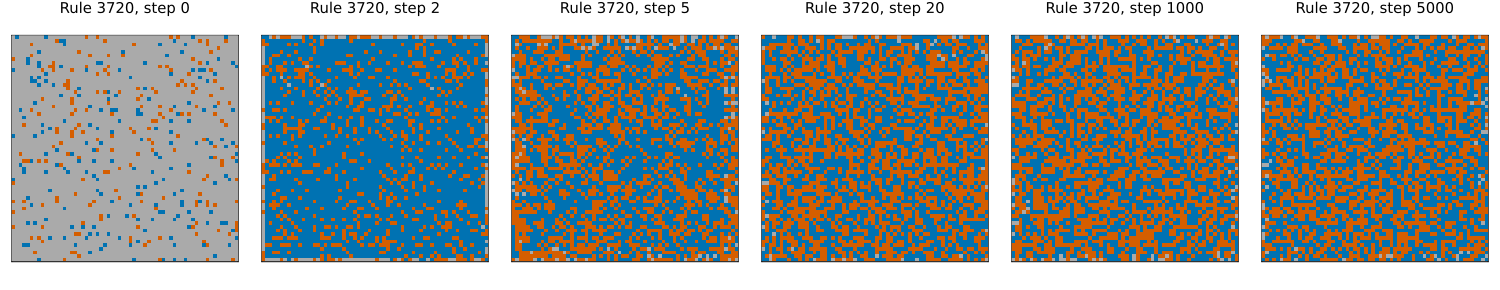

In [7]:
let

    # draw one grid for each step -
    panels = [];
    for t ∈ steps_to_visualize
        push!(panels, plot_grid(market.frames[t]; colors = intention_colors, title_text = "Rule $(baseline_rule), step $(t)"));
    end

    # show the grids in one row -
    number_of_panels = length(steps_to_visualize);
    plot(panels..., layout = (1, number_of_panels), size = (250*number_of_panels, 290), margin = 1Plots.mm)
end

> __What do we see?__
>
> * __The start:__ At the first step shown, most traders hold, and a few scattered traders intend to buy or sell.
> * __The first steps:__ The grid changes quickly, because every trader reads its next intention from the table at each step.
> * __The later steps:__ When the later grids look alike, the market has settled into the mix of intentions that the rule keeps.

Next, let's follow the intentions and the share price. The dealer quotes the share price from its cash and shares. Net buying raises the price, and net selling lowers it.

Set `steps_to_plot` to choose how many steps the plots show:

In [8]:
steps_to_plot = 2000; # the plots show steps 0 to steps_to_plot

`Unhide` the code block below to see how we plotted the fractions of the three intentions and the share price.

Does the share price follow the intentions?

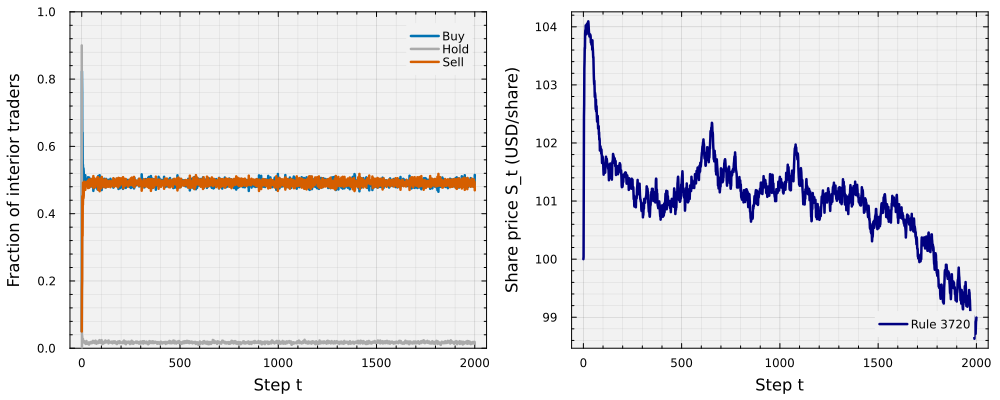

In [9]:
let

    # initialize: the steps we plot; index t + 1 of each series holds step t -
    last_step = min(steps_to_plot, number_of_steps);
    plotted_steps = 0:last_step;
    index_range = 1:(last_step + 1);

    # left panel: the fraction of interior traders with each intention -
    p_fraction = plot(plotted_steps, market.buy_fraction[index_range], lw = 2.5, c = intention_colors[1], label = "Buy",
        bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent,
        xminorticks = true, yminorticks = true, minorgrid = true, ylims = (0.0, 1.0), legend = :topright);
    plot!(p_fraction, plotted_steps, market.hold_fraction[index_range], lw = 2.5, c = intention_colors[2], label = "Hold");
    plot!(p_fraction, plotted_steps, market.sell_fraction[index_range], lw = 2.5, c = intention_colors[3], label = "Sell");
    xlabel!(p_fraction, "Step t", fontsize = 18);
    ylabel!(p_fraction, "Fraction of interior traders", fontsize = 18);

    # right panel: the share price that the dealer quotes -
    p_price = plot(plotted_steps, market.prices[index_range], lw = 2.5, c = color_rule, label = "Rule $(baseline_rule)",
        bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent,
        xminorticks = true, yminorticks = true, minorgrid = true, legend = :bottomright);
    xlabel!(p_price, "Step t", fontsize = 18);
    ylabel!(p_price, "Share price S_t (USD/share)", fontsize = 18);

    # show the two panels side by side -
    plot(p_fraction, p_price, layout = (1, 2), size = (1000, 400), bottom_margin = 5Plots.mm, left_margin = 5Plots.mm)
end

> __What do we see?__
>
> * __Intentions:__ The fractions of the three intentions change in the first few steps. They stay level once the market has settled into its mix.
> * __Share price:__ The share price rises while more traders buy than sell, and it falls while more traders sell than buy.
> * __The price levels off:__ A trader can buy only with the cash it holds, and can sell only the shares it holds. When many orders fail for lack of cash or shares, the share price stops moving, even if the Buy and Sell fractions stay apart.

Let's compare our first market rule with a second market that follows a different rule. 

___

## Task 3: Compare Two Rules
In this task, we run a second market that follows `switch_rule`, and compare it with the first market. The second market has the same starting market, the same dealer, and the same noise as the first. Only the rule differs.

We store the entries of the second rule in the `entries_to_compare::Vector{Int64}` variable, and the second market in the `market_to_compare::MyModelBSimulationResult` variable:

In [10]:
(entries_to_compare, market_to_compare) = let

    # get the entries of the second rule -
    table = WM.rule_table(switch_rule);

    # the random-edge probabilities only matter for :random edge traders -
    kw = NamedTuple();
    if boundary_mode == :random
        kw = (random_edge_probabilities = random_probabilities,);
    end

    # run the second market with the settings of the first market, and time it -
    saved_steps = collect(0:number_of_steps);
    t_run = @elapsed result = run_rule_market(; rule = switch_rule, L = L, h = h, seed = seed, boundary_mode = boundary_mode,
        steps = number_of_steps, σ_S = σ_S, Δt = Δt, snapshot_steps = saved_steps, kw...);
    println("run time: $(round(t_run; digits = 1)) seconds; saved grids: $(length(saved_steps))");

    # checks -
    @assert result.frames[0] == market.frames[0] "the two markets start from the same grid"
    @assert result.prices[1] == market.prices[1] "the two markets start from the same share price"

    # return -
    (table, result)
end;

run time: 0.9 seconds; saved grids: 5001


`Unhide` the code block below to see how we drew the tables of the two rules. The top table is `baseline_rule`, and the bottom table is `switch_rule`.

At which sums do the two rules give a different next intention?

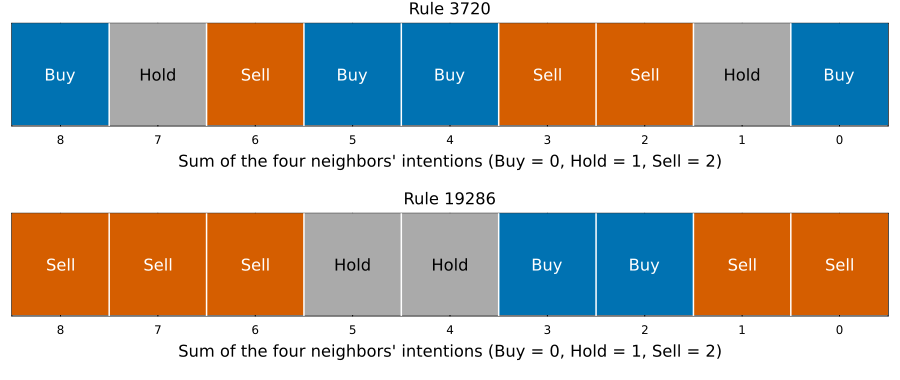

In [11]:
let

    # draw the table of each rule: sum 8 on the left, sum 0 on the right -
    p_rule = plot_rule(entries; colors = intention_colors, names = intention_names, title_text = "Rule $(baseline_rule)");
    p_compare = plot_rule(entries_to_compare; colors = intention_colors, names = intention_names, title_text = "Rule $(switch_rule)");

    # show the first rule on top and the second rule below it -
    plot(p_rule, p_compare, layout = (2, 1), size = (900, 380))
end

`Unhide` the code block below to see how we drew the grids of the two markets at the same steps. The top row follows `baseline_rule`, and the bottom row follows `switch_rule`.

When do the two grids part?

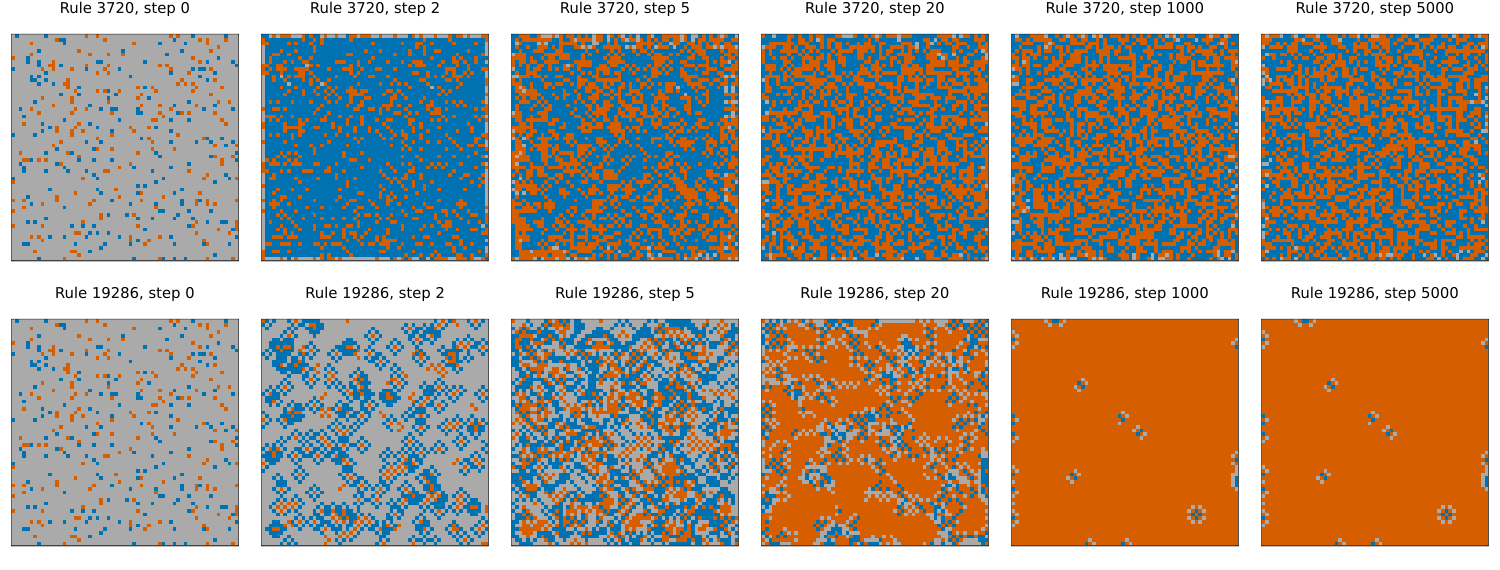

In [12]:
let

    # draw the top row: the first market at each step -
    panels = [];
    for t ∈ steps_to_visualize
        push!(panels, plot_grid(market.frames[t]; colors = intention_colors, title_text = "Rule $(baseline_rule), step $(t)"));
    end

    # draw the bottom row: the second market at the same steps -
    for t ∈ steps_to_visualize
        push!(panels, plot_grid(market_to_compare.frames[t]; colors = intention_colors, title_text = "Rule $(switch_rule), step $(t)"));
    end

    # show the two rows: the layout fills the top row first -
    number_of_panels = length(steps_to_visualize);
    plot(panels..., layout = (2, number_of_panels), size = (250*number_of_panels, 570), margin = 1Plots.mm)
end

> __What do we see?__
>
> * __The same start:__ The two markets start from the same grid.
> * __The grids part:__ The two grids stay alike until traders reach a sum at which the two rules differ. From then on, the grids move apart.
> * __The later steps:__ The later grids show the mix of intentions that each rule keeps.

`Unhide` the code block below to see how we plotted the share prices of the two markets.

What does the second rule do to the share price?

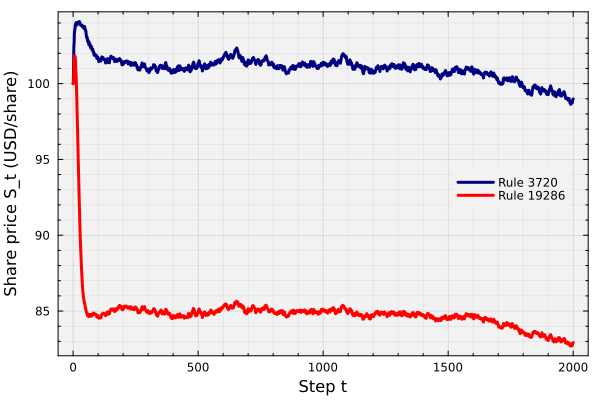

In [13]:
let

    # initialize: the steps we plot; index t + 1 of each series holds step t -
    last_step = min(steps_to_plot, number_of_steps);
    plotted_steps = 0:last_step;
    index_range = 1:(last_step + 1);

    # plot: the share price of each market -
    q = plot(plotted_steps, market.prices[index_range], lw = 3, c = color_rule, label = "Rule $(baseline_rule)",
        bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent,
        xminorticks = true, yminorticks = true, minorgrid = true, legend = :right);
    plot!(q, plotted_steps, market_to_compare.prices[index_range], lw = 3, c = color_compare, label = "Rule $(switch_rule)");
    xlabel!(q, "Step t", fontsize = 18);
    ylabel!(q, "Share price S_t (USD/share)", fontsize = 18)
end

Both share prices start at the same value. The two prices move apart once the two grids differ, because the two markets then send different orders to the dealer.

Here every trader followed the second rule from the first step. Next, we ask what happens when only a fraction of the traders change rules partway through a market.

___

## Summary
In this example, we read the table of a rule and ran a market in which every interior trader follows that rule. We then ran a second market under a different rule and compared the two markets.

> __Key Takeaways:__
>
> * __A rule number is a table:__ We read the rule number in base 3 to get nine entries, one for each sum of the four neighbors' intentions. Each entry is the next intention of a trader whose neighbors have that sum.
> * __One rule sets the mix on the grid:__ We gave the rule to every interior trader and saved the grid at each step. The grid moved from its start to the mix of intentions that the rule keeps, and the share price followed the balance of buyers and sellers.
> * __A different rule gives a different market:__ We ran a second market from the same start under a second rule. The two grids moved apart once traders reached a sum at which the two rules differ, and the two share prices moved apart with them.

We can now change either rule number and see what the new rule does to the grid and to the share price.
___

## Disclaimer and Risks
__This content is offered solely for training and informational purposes__. No offer or solicitation to buy or sell securities or derivative products or any investment or trading advice or strategy is made, given, or endorsed by the teaching team.

__Trading involves risk__. Carefully review your financial situation before investing in securities, futures contracts, options, or commodity interests. Past performance, whether actual or indicated by historical tests of strategies, is no guarantee of future performance or success. Trading is generally inappropriate for someone with limited resources, investment or trading experience, or a low-risk tolerance. Only risk capital that is not required for living expenses should be used.

__You are fully responsible for any investment or trading decisions you make__. Such decisions should be based solely on evaluating your financial circumstances, investment or trading objectives, risk tolerance, and liquidity needs.

___